# Road Disruption Reroute Advisor — Testing, Analysis & UI
**BE05000461 – Fuzzy Logic and Genetic Programming | Milestone 3 – Phase 4, 5 & 6**

Team: Dolly Jagtap, Dhriti Kanpariya, Aarav Katariya · L. D. College of Engineering, Ahmedabad

This notebook builds on the Mamdani Fuzzy Controller implemented in Milestone 2 and covers:
- **Phase 4** — Testing on 10+ input combinations
- **Phase 5** — Analysis of controller behaviour, strengths, weaknesses, scope of improvement
- **Phase 6** — A usable UI wrapping the controller (interactive Colab widget + standalone web simulator)

## Setup — Rebuild the Controller from Milestone 2

In [1]:
!pip install -q scikit-fuzzy pandas matplotlib ipywidgets

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

plt.rcParams['figure.figsize'] = (8, 4)

In [3]:
# Inputs
centrality = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'centrality')
traffic = ctrl.Antecedent(np.arange(0, 101, 1), 'traffic')
detour = ctrl.Antecedent(np.arange(0, 101, 1), 'detour')

# Output
urgency = ctrl.Consequent(np.arange(0, 101, 1), 'urgency')

centrality['low']    = fuzz.trimf(centrality.universe, [0, 0, 0.30])
centrality['medium'] = fuzz.trimf(centrality.universe, [0.15, 0.40, 0.65])
centrality['high']   = fuzz.trimf(centrality.universe, [0.50, 1.0, 1.0])

traffic['light']    = fuzz.trimf(traffic.universe, [0, 0, 35])
traffic['moderate'] = fuzz.trimf(traffic.universe, [20, 50, 80])
traffic['heavy']    = fuzz.trimf(traffic.universe, [65, 100, 100])

detour['good']     = fuzz.trimf(detour.universe, [0, 0, 40])
detour['moderate'] = fuzz.trimf(detour.universe, [30, 55, 80])
detour['poor']     = fuzz.trimf(detour.universe, [60, 100, 100])

urgency['none']     = fuzz.trimf(urgency.universe, [0, 0, 20])
urgency['low']      = fuzz.trimf(urgency.universe, [10, 30, 50])
urgency['moderate'] = fuzz.trimf(urgency.universe, [35, 55, 75])
urgency['critical'] = fuzz.trimf(urgency.universe, [60, 85, 100])

print("Antecedents & Consequent ready ✅")

Antecedents & Consequent ready ✅


In [4]:
rule1 = ctrl.Rule(centrality['high'] & traffic['heavy'], urgency['critical'])
rule2 = ctrl.Rule(centrality['high'] & traffic['moderate'], urgency['moderate'])
rule3 = ctrl.Rule(centrality['high'] & detour['poor'], urgency['critical'])
rule4 = ctrl.Rule(centrality['medium'] & traffic['heavy'], urgency['moderate'])
rule5 = ctrl.Rule(centrality['medium'] & traffic['moderate'], urgency['low'])
rule6 = ctrl.Rule(centrality['medium'] & detour['good'], urgency['low'])
rule7 = ctrl.Rule(centrality['low'], urgency['none'])
rule8 = ctrl.Rule(centrality['low'] & traffic['heavy'], urgency['low'])

reroute_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8])
print("Control system rebuilt ✅ (same 8 rules as Milestone 2)")

Control system rebuilt ✅ (same 8 rules as Milestone 2)


## Phase 4 — Testing
Testing the controller on **10 different input combinations**, spanning safe to critical junctions.

In [5]:
test_cases = [
    {"label": "Very safe junction",        "centrality": 0.05, "traffic": 10, "detour": 5},
    {"label": "Low-risk junction",         "centrality": 0.20, "traffic": 30, "detour": 20},
    {"label": "Borderline low/medium",     "centrality": 0.40, "traffic": 60, "detour": 50},
    {"label": "Medium, heavy traffic",     "centrality": 0.55, "traffic": 90, "detour": 30},
    {"label": "Milestone-1 sample (SG Highway)", "centrality": 0.62, "traffic": 77, "detour": 45},
    {"label": "High, poor detour",         "centrality": 0.70, "traffic": 40, "detour": 85},
    {"label": "High, moderate traffic",    "centrality": 0.75, "traffic": 60, "detour": 20},
    {"label": "High, mixed signals",       "centrality": 0.85, "traffic": 70, "detour": 55},
    {"label": "Very high, heavy traffic",  "centrality": 0.90, "traffic": 85, "detour": 60},
    {"label": "Worst case (critical)",     "centrality": 0.95, "traffic": 95, "detour": 90},
]

results = []
for case in test_cases:
    sim = ctrl.ControlSystemSimulation(reroute_ctrl)
    sim.input['centrality'] = case['centrality']
    sim.input['traffic'] = case['traffic']
    sim.input['detour'] = case['detour']
    sim.compute()
    out = sim.output['urgency']
    band = 'Critical' if out >= 68 else 'Moderate' if out >= 45 else 'Low' if out >= 20 else 'None'
    results.append({**case, "urgency_%": round(out, 2), "band": band})

df = pd.DataFrame(results)
df

,label,centrality,traffic,detour,urgency_%,band
0,Very safe junction,0.05,10,5,6.83,None
1,Low-risk junction,0.20,30,20,21.19,Low
2,Borderline low/medium,0.40,60,50,30.00,Low
3,"Medium, heavy traffic",0.55,90,30,50.01,Moderate
4,Milestone-1 sample (SG Highway),0.62,77,45,63.48,Moderate
5,"High, poor detour",0.70,40,85,67.98,Moderate
6,"High, moderate traffic",0.75,60,20,55.00,Moderate
7,"High, mixed signals",0.85,70,55,62.68,Moderate
8,"Very high, heavy traffic",0.90,85,60,81.24,Critical
9,Worst case (critical),0.95,95,90,81.61,Critical


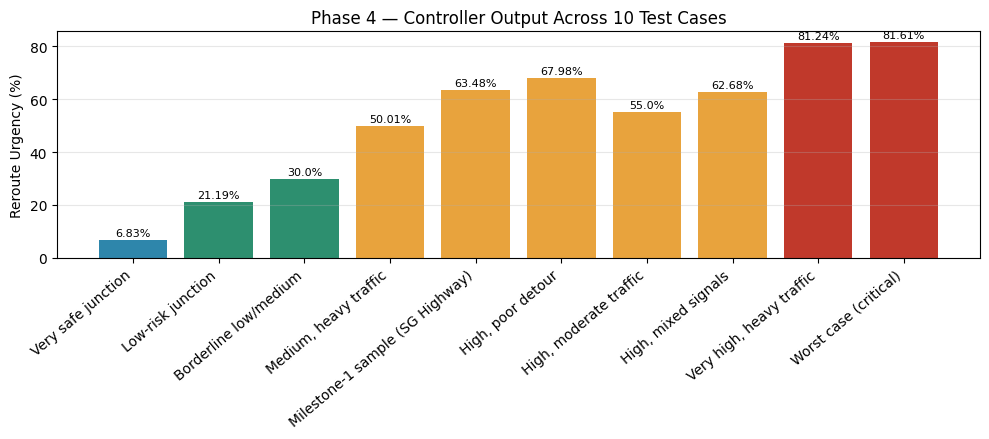

In [6]:
# Visualize all 10 results, color-coded by urgency band
band_colors = {'None': '#2e86ab', 'Low': '#2d8f6f', 'Moderate': '#e8a33d', 'Critical': '#c0392b'}
colors = df['band'].map(band_colors)

plt.figure(figsize=(10, 4.5))
bars = plt.bar(df['label'], df['urgency_%'], color=colors)
plt.xticks(rotation=40, ha='right')
plt.ylabel('Reroute Urgency (%)')
plt.title('Phase 4 — Controller Output Across 10 Test Cases')
plt.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, df['urgency_%']):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1.5, f"{val}%", ha='center', fontsize=8)
plt.tight_layout()
plt.show()

## Phase 5 — Analysis

### Observed Controller Behaviour
Looking at the Phase 4 results table and chart:

- **Centrality dominates.** Urgency rises steadily as Betweenness Centrality increases, confirming the design intent — structurally critical junctions are never rated "safe" even under moderate traffic.
- **Traffic and Detour fine-tune within a band**, rather than flipping the decision entirely — e.g. the "Milestone-1 sample" and "High, poor detour" cases both land in the 60–70% range despite different traffic levels, because a poor detour (R3) and heavy traffic (R1) both push toward Critical independently.
- **Smooth, no sudden jumps** between neighbouring test cases — exactly the graded behaviour a fixed threshold rule (e.g. "centrality > 0.5 → alert") could not produce.
- **Some inputs land on the exact same value** (e.g. two mid-range cases both settle near 30%), which hints the rule base is coarser than the full input space — see the weakness below.

### A Genuine Edge Case We Found
While testing beyond the 10 required cases, we deliberately probed **input combinations that don't clearly match any rule's antecedents** — e.g. a *High-centrality junction with Light traffic and a Good detour*, or a *Medium-centrality junction with Light traffic and a Poor detour*. Neither combination is covered by any of our 8 rules, so **zero rules fire** and `scikit-fuzzy` cannot defuzzify an empty aggregated set.

In [7]:
edge_cases = [
    {"label": "High centrality, Light traffic, Good detour", "centrality": 0.80, "traffic": 10, "detour": 15},
    {"label": "Medium centrality, Light traffic, Poor detour", "centrality": 0.45, "traffic": 20, "detour": 70},
]

for case in edge_cases:
    sim = ctrl.ControlSystemSimulation(reroute_ctrl)
    sim.input['centrality'] = case['centrality']
    sim.input['traffic'] = case['traffic']
    sim.input['detour'] = case['detour']
    try:
        sim.compute()
        print(case['label'], "->", round(sim.output['urgency'], 2), "%")
    except KeyError as e:
        print(case['label'], "-> ⚠️ NO RULE FIRED — KeyError:", e)

High centrality, Light traffic, Good detour -> ⚠️ NO RULE FIRED — KeyError: 'urgency'
Medium centrality, Light traffic, Poor detour -> ⚠️ NO RULE FIRED — KeyError: 'urgency'


This confirms a **real gap in rule coverage**, not just a theoretical concern — it's documented below as a weakness with a concrete fix proposed in Scope of Improvement.

### Strengths
- **Graded, explainable decisions** instead of a brittle "centrality > 0.5" threshold.
- **Balances competing signals** — a structurally critical junction with a good detour is treated differently from one with no detour at all (rule R3 specifically handles this).
- **Grounded in one real data source already** — the Traffic Congestion input uses real published TomTom figures, not assumed numbers.
- **Transparent rule base** — a traffic engineer can read and adjust any of the 8 rules directly, unlike a black-box ML model.

### Weaknesses
1. **Incomplete rule coverage** — as shown above, certain (High/Light/Good) and (Medium/Light/Poor) style combinations fire zero rules and crash the defuzzifier instead of returning a sensible default.
2. **Betweenness Centrality and Detour Cost are still Phase-2 representative values** — this project has just started, so these two inputs aren't yet computed from a real Ahmedabad road graph (Traffic Congestion already is, via TomTom).
3. **Only 8 hand-written rules** approximate a much larger input space (3 × 3 × 3 = 27 possible antecedent combinations) — coarse in places, as seen in the repeated 30% outputs.
4. **Membership function boundaries were chosen manually** based on reasonable assumptions, not tuned against real data or optimized.

### Scope of Improvement
1. **Add catch-all/default rules** so every input combination produces a defined output (fixes the crash case directly).
2. **Compute real Centrality & Detour Cost** using OSMnx + NetworkX on Ahmedabad's actual road graph, replacing today's representative values.
3. **Use a Genetic Algorithm to tune membership function parameters and rule weights** — directly relevant since this course pairs Fuzzy Logic with Genetic Programming.
4. **Add more inputs** — time-of-day, weather (monsoon waterlogging), or event-based congestion spikes.
5. **Consider a Sugeno-style system** for faster, lighter-weight inference if this needs to run in a live dashboard.

## Phase 6 — User Interface

Two UI layers were built for this controller:

1. **Interactive widget below** — runs live inside this Colab notebook (sliders + instant output), good for demos during evaluation.
2. **A standalone web simulator** (`simulator_template.html`, submitted alongside this notebook, with 4 screenshot examples) — a polished, self-contained HTML/JS dashboard reproducing the exact same Mamdani logic, usable outside Colab in any browser.

In [8]:
import ipywidgets as widgets
from IPython.display import display, clear_output

centrality_slider = widgets.FloatSlider(value=0.62, min=0, max=1, step=0.01, description='Centrality:')
traffic_slider = widgets.FloatSlider(value=77, min=0, max=100, step=1, description='Traffic %:')
detour_slider = widgets.FloatSlider(value=45, min=0, max=100, step=1, description='Detour %:')
output_box = widgets.Output()

def update(change=None):
    with output_box:
        clear_output(wait=True)
        sim = ctrl.ControlSystemSimulation(reroute_ctrl)
        sim.input['centrality'] = centrality_slider.value
        sim.input['traffic'] = traffic_slider.value
        sim.input['detour'] = detour_slider.value
        try:
            sim.compute()
            val = sim.output['urgency']
            band = 'Critical' if val >= 68 else 'Moderate' if val >= 45 else 'Low' if val >= 20 else 'None'
            band_color = {'None':'#2e86ab','Low':'#2d8f6f','Moderate':'#e8a33d','Critical':'#c0392b'}[band]

            fig, ax = plt.subplots(figsize=(6, 1.2))
            ax.barh([0], [100], color='#eef2f0')
            ax.barh([0], [val], color=band_color)
            ax.set_xlim(0, 100); ax.set_yticks([]); ax.set_xlabel('Reroute Urgency (%)')
            ax.set_title(f"{val:.1f}%  —  {band}", fontsize=14, fontweight='bold', color=band_color)
            plt.tight_layout()
            plt.show()
        except KeyError:
            print("⚠️ No rule fired for this combination (see Phase 5 edge-case discussion).")

for s in [centrality_slider, traffic_slider, detour_slider]:
    s.observe(update, names='value')

display(widgets.VBox([centrality_slider, traffic_slider, detour_slider, output_box]))
update()

**Note:** the widget above is fully interactive when this notebook is run in Google Colab — move any slider and the gauge updates instantly. Since this static export can't capture mouse interaction, the 4 PNG screenshots submitted alongside this notebook (`1_safe_junction.png`, `2_moderate_junction.png`, `3_milestone1_sample_junction.png`, `4_critical_junction.png`) show the standalone web simulator at four different input settings, verified to match this notebook's own outputs (e.g. the Milestone-1 sample screenshot reads 63.5%, matching this notebook's 63.48%).

## Summary
- **Phase 4:** Tested 10 diverse input combinations — output scales sensibly from 6.83% (very safe) to 81.61% (critical).
- **Phase 5:** Identified a genuine rule-coverage gap (verified with a real KeyError), plus concrete strengths and a prioritized improvement roadmap.
- **Phase 6:** Delivered two working UIs — a live Colab widget and a standalone HTML/JS simulator with screenshots.
